# Pemodelan SARIMA untuk Prediksi Air Quality Index (AQI)

Notebook ini digunakan untuk membangun dan mengevaluasi model
SARIMA dalam memprediksi rata-rata AQI harian pada perangkat
Jl. Lapangan Rajawali.

Tahapan meliputi persiapan data, pembagian training-testing,
identifikasi parameter, pemodelan, prediksi, dan evaluasi
menggunakan MAE, RMSE, serta MAPE.

# 1. Mengimpor library

In [1]:
import pandas as pd
import numpy as np

# Membaca hanya kolom yang diperlukan
df = pd.read_parquet(
    "data/dataset_aqi_gabungan.parquet",
    columns=["updated_at", "device", "aqi"]
)

print("Ukuran dataset:", df.shape)
print("Jumlah perangkat:", df["device"].nunique())

display(df.head())

Ukuran dataset: (3456348, 3)
Jumlah perangkat: 83


,updated_at,device,aqi
0,2026-06-19 10:25:42,Ibu Andri,0
1,2026-06-19 10:25:42,Bpk Dhona,19
2,2026-06-19 10:25:42,Pak Kasun Win,16
3,2026-06-19 10:25:41,Balai Desa Sarimulyo,74
4,2026-06-19 10:25:41,Bpk Imam Muslih,24


# 2. Membuat AQI Harian

In [2]:
# 2. Menyiapkan seri AQI harian

nama_perangkat = "Jl. Lapangan Rajawali"

data_perangkat = df[
    (df["device"] == nama_perangkat)
    & (df["aqi"].notna())
].copy()

# Memastikan kolom waktu bertipe datetime
data_perangkat["updated_at"] = pd.to_datetime(
    data_perangkat["updated_at"]
)

# Membuat tanggal harian
data_perangkat["tanggal"] = (
    data_perangkat["updated_at"].dt.normalize()
)

# Menghitung rata-rata AQI harian
aqi_harian = (
    data_perangkat.groupby("tanggal")["aqi"]
    .mean()
    .sort_index()
    .to_frame(name="aqi")
)

# Mengambil periode kontinu untuk eksperimen awal
data_kontinu = aqi_harian.loc[
    "2025-11-03":"2026-02-18"
].copy()

print("Perangkat:", nama_perangkat)
print("Jumlah hari:", len(data_kontinu))
print("AQI kosong:", data_kontinu["aqi"].isna().sum())

display(data_kontinu.head())
display(data_kontinu.tail())

Perangkat: Jl. Lapangan Rajawali
Jumlah hari: 108
AQI kosong: 0


,aqi
tanggal,
2025-11-03,67.871795
2025-11-04,57.123967
2025-11-05,42.314050
2025-11-06,8.365854
2025-11-07,27.290598


,aqi
tanggal,
2026-02-14,5.917160
2026-02-15,14.964497
2026-02-16,10.331034
2026-02-17,32.234940
2026-02-18,37.314607


# 3. Membagi data training dan testing

In [3]:
# 3. Membagi data training dan testing

n_train = int(len(data_kontinu) * 0.8)

train = data_kontinu.iloc[:n_train].copy()
test = data_kontinu.iloc[n_train:].copy()

print("Jumlah data keseluruhan:", len(data_kontinu))
print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train.index.min(), "sampai", train.index.max())

print("\nPeriode testing:")
print(test.index.min(), "sampai", test.index.max())

Jumlah data keseluruhan: 108
Jumlah data training: 86
Jumlah data testing: 22

Periode training:
2025-11-03 00:00:00 sampai 2026-01-27 00:00:00

Periode testing:
2026-01-28 00:00:00 sampai 2026-02-18 00:00:00


80:20 

Training 86	3 Nov 2025–27 Jan 2026

Testing 22	28 Jan–18 Feb 2026

# 4. Melatih baseline ARIMA

In [4]:
# 4. Melatih model baseline ARIMA(1,0,1)

from statsmodels.tsa.statespace.sarimax import SARIMAX

model_arima = SARIMAX(
    train["aqi"],
    order=(1, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_arima = model_arima.fit(disp=False)

print("Model: ARIMA(1,0,1)")
print("AIC:", hasil_arima.aic)
print("BIC:", hasil_arima.bic)

Model: ARIMA(1,0,1)
AIC: 673.2200175684286
BIC: 682.9432847638019


d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


# 5. Menguji kandidat SARIMA musiman

In [5]:
# 5. Melatih kandidat SARIMA musiman

model_sarima = SARIMAX(
    train["aqi"],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 0, 7),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_sarima = model_sarima.fit(disp=False)

print("Model: SARIMA(1,0,1)(1,0,0,7)")
print("AIC:", hasil_sarima.aic)
print("BIC:", hasil_sarima.bic)

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Model: SARIMA(1,0,1)(1,0,0,7)
AIC: 602.7335600562535
BIC: 614.5171041897015


Membandingkan hasil ARIMA dan SARIMA
hasil eksperimen:
		
ARIMA(1,0,1)	AIC 673,2200	BIC 682,9433

SARIMA(1,0,1)(1,0,0,7)	AIC 602,7336	BIC 614,5171

Perbedaan AIC:673,220-602,7336= 70,4864

Perbedaan BIC: 682,9433-614,171= 684262

AIC dan BIC SARIMA lebih rendah daripada baseline ARIMA. indikasi kuat kanddat sarima memiliki kecooka pada data testing dengan mempertimbangkan kompleksitas model.

# 6. Menghasilkan prediksi SARIMA pada data tesing

In [6]:
# 6. Memprediksi AQI menggunakan SARIMA

prediksi_sarima = hasil_sarima.forecast(
    steps=len(test)
)

hasil_prediksi_sarima = pd.DataFrame({
    "AQI_Aktual": test["aqi"],
    "AQI_Prediksi": prediksi_sarima
})

display(hasil_prediksi_sarima)

,AQI_Aktual,AQI_Prediksi
2026-01-28,17.951087,28.204372
2026-01-29,31.074866,26.307020
2026-01-30,27.474359,25.168864
2026-01-31,10.000000,24.383220
2026-02-01,1.640000,24.110781
2026-02-02,10.356688,23.161357
2026-02-03,8.025478,23.339537
2026-02-04,4.783439,23.419887
2026-02-05,12.936306,23.477481
2026-02-06,7.068182,23.513060


# 7. Menghitung MAE, RMSE, dan MAPE SARIMA 

In [7]:
# 7. Evaluasi model SARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

aktual = hasil_prediksi_sarima["AQI_Aktual"]
prediksi = hasil_prediksi_sarima["AQI_Prediksi"]

mae_sarima = mean_absolute_error(aktual, prediksi)

rmse_sarima = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mape_sarima = np.mean(
    np.abs((aktual - prediksi) / aktual)
) * 100

print("Evaluasi SARIMA(1,0,1)(1,0,0,7)")
print("--------------------------------")
print(f"MAE  : {mae_sarima:.4f}")
print(f"RMSE : {rmse_sarima:.4f}")
print(f"MAPE : {mape_sarima:.2f}%")

Evaluasi SARIMA(1,0,1)(1,0,0,7)
--------------------------------
MAE  : 11.9011
RMSE : 13.1955
MAPE : 193.95%


# 8. Perbandingan Hasil Evaluasi ARIMA dan SARIMA

| Metrik | ARIMA | SARIMA | Perubahan |
|---|---:|---:|---:|
| MAE | 12,5757 | 11,9011 | Turun 5,36% |
| RMSE | 13,9512 | 13,1955 | Turun 5,42% |
| MAPE | 205,41% | 193,95% | Turun 5,58% |

**Interpretasi:**

Model SARIMA menunjukkan peningkatan kinerja dibandingkan model ARIMA pada ketiga metrik evaluasi. Nilai MAE menurun sebesar 5,36%, RMSE sebesar 5,42%, dan MAPE sebesar 5,58%.

Hasil ini menunjukkan bahwa penambahan komponen musiman mingguan membantu mengurangi kesalahan prediksi AQI pada periode pengujian. Namun, nilai MAPE yang masih tinggi menunjukkan bahwa prediksi perlu dievaluasi lebih lanjut, terutama karena MAPE sensitif terhadap nilai AQI aktual yang rendah.

Hasil ini masih merupakan eksperimen awal dengan 22 hari data pengujian dan belum dapat dijadikan kesimpulan akhir mengenai model terbaik.


# 9. Menyimpan hasil evaluasi sarima

In [8]:
# Langkah 10: Menyimpan hasil evaluasi SARIMA

hasil_evaluasi_sarima = pd.DataFrame({
    "Model": ["SARIMA(1,0,1)(1,0,0,7)"],
    "AIC": [hasil_sarima.aic],
    "BIC": [hasil_sarima.bic],
    "MAE": [mae_sarima],
    "RMSE": [rmse_sarima],
    "MAPE": [mape_sarima]
})

hasil_evaluasi_sarima.to_csv(
    "evaluasi_sarima_baseline.csv",
    index=False
)

hasil_prediksi_sarima.to_csv(
    "prediksi_sarima_baseline.csv",
    index=True
)

display(hasil_evaluasi_sarima)

print("Hasil evaluasi dan prediksi SARIMA berhasil disimpan.")

,Model,AIC,BIC,MAE,RMSE,MAPE
0,"SARIMA(1,0,1)(1,0,0,7)",602.73356,614.517104,11.9011,13.195496,193.946823


Hasil evaluasi dan prediksi SARIMA berhasil disimpan.


# 10. Menguji kandidat berdasarkan AIC dan BIC

In [9]:
# Langkah 12: Membandingkan beberapa kandidat SARIMA

from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

kandidat_sarima = {
    "SARIMA(1,0,1)(1,0,0,7)": ((1, 0, 1), (1, 0, 0, 7)),
    "SARIMA(1,0,0)(1,0,0,7)": ((1, 0, 0), (1, 0, 0, 7)),
    "SARIMA(0,0,1)(1,0,0,7)": ((0, 0, 1), (1, 0, 0, 7)),
    "SARIMA(1,0,1)(0,0,1,7)": ((1, 0, 1), (0, 0, 1, 7)),
    "SARIMA(0,0,1)(0,0,1,7)": ((0, 0, 1), (0, 0, 1, 7))
}

hasil_kandidat = []

for nama, (order, seasonal_order) in kandidat_sarima.items():
    try:
        model = SARIMAX(
            train["aqi"],
            order=order,
            seasonal_order=seasonal_order,
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        hasil = model.fit(disp=False)

        hasil_kandidat.append({
            "Model": nama,
            "AIC": hasil.aic,
            "BIC": hasil.bic,
            "Konvergen": hasil.mle_retvals.get(
                "converged", False
            )
        })

    except Exception as e:
        print(f"Gagal melatih {nama}: {e}")

tabel_kandidat = pd.DataFrame(hasil_kandidat)

display(
    tabel_kandidat.sort_values("AIC").reset_index(drop=True)
)

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.p

,Model,AIC,BIC,Konvergen
0,"SARIMA(1,0,1)(0,0,1,7)",592.261359,603.980386,True
1,"SARIMA(0,0,1)(0,0,1,7)",598.034160,607.409382,True
2,"SARIMA(1,0,0)(1,0,0,7)",600.835248,610.262084,True
3,"SARIMA(1,0,1)(1,0,0,7)",602.733560,614.517104,True
4,"SARIMA(0,0,1)(1,0,0,7)",623.563682,633.041473,True


AIC dan BIC yang lebih rendah umumnya lebih disukai ketika membandingkan model pada data yang sama.

Konvergen = True menunjukkan bahwa prosedur estimasi melaporkan telah konvergen. Ini penting, meskipun belum menjamin model sudah memadai.

Kandidat dengan AIC terendah belum tentu memiliki prediksi testing terbaik.

# 11. Menguji seluruh kandidat

In [10]:
# Langkah 14: Evaluasi seluruh kandidat SARIMA pada data testing

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

hasil_evaluasi_kandidat = []

for nama, (order, seasonal_order) in kandidat_sarima.items():

    model = SARIMAX(
        train["aqi"],
        order=order,
        seasonal_order=seasonal_order,
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    hasil = model.fit(disp=False)

    # Prediksi 22 hari ke depan
    prediksi = hasil.forecast(steps=len(test))

    # Menghitung metrik evaluasi
    aktual = test["aqi"].to_numpy()
    prediksi = np.asarray(prediksi)

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))
    mape = np.mean(np.abs((aktual - prediksi) / aktual)) * 100

    hasil_evaluasi_kandidat.append({
        "Model": nama,
        "AIC": hasil.aic,
        "BIC": hasil.bic,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi_kandidat)

display(
    tabel_evaluasi.sort_values("RMSE").reset_index(drop=True)
)

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.p

,Model,AIC,BIC,MAE,RMSE,MAPE
0,"SARIMA(1,0,1)(0,0,1,7)",592.261359,603.980386,11.658289,12.890715,189.338023
1,"SARIMA(0,0,1)(0,0,1,7)",598.034160,607.409382,11.841080,13.104728,192.997913
2,"SARIMA(1,0,0)(1,0,0,7)",600.835248,610.262084,11.866124,13.169378,193.544986
3,"SARIMA(1,0,1)(1,0,0,7)",602.733560,614.517104,11.901100,13.195496,193.946823
4,"SARIMA(0,0,1)(1,0,0,7)",623.563682,633.041473,12.435526,13.787673,202.692483


SARIMA(1,0,1)(0,0,1,7) menjadi kandidat terbaik di antara lima konfigurasi yang diuji.
- AIC dan BIC paling rendah.
- MAE terendah, yaitu 11,6583.
- RMSE terendah, yaitu 12,8907.
- MAPE terendah, yaitu 189,34%

# 12. Memeriksa hasil kandidat terbaik pada data testing

In [11]:
# Langkah 16: Prediksi kandidat SARIMA terbaik

order_terbaik = (1, 0, 1)
seasonal_order_terbaik = (0, 0, 1, 7)

model_sarima_terbaik = SARIMAX(
    train["aqi"],
    order=order_terbaik,
    seasonal_order=seasonal_order_terbaik,
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_sarima_terbaik = model_sarima_terbaik.fit(disp=False)

prediksi_terbaik = hasil_sarima_terbaik.forecast(
    steps=len(test)
)

hasil_prediksi_terbaik = pd.DataFrame({
    "AQI_Aktual": test["aqi"],
    "AQI_Prediksi": prediksi_terbaik
})

display(hasil_prediksi_terbaik)

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,AQI_Aktual,AQI_Prediksi
2026-01-28,17.951087,27.489536
2026-01-29,31.074866,25.537708
2026-01-30,27.474359,24.426776
2026-01-31,10.000000,23.711513
2026-02-01,1.640000,23.678759
2026-02-02,10.356688,22.049106
2026-02-03,8.025478,22.570980
2026-02-04,4.783439,22.953928
2026-02-05,12.936306,23.107773
2026-02-06,7.068182,23.177360


In [13]:
import matplotlib.pyplot as plt

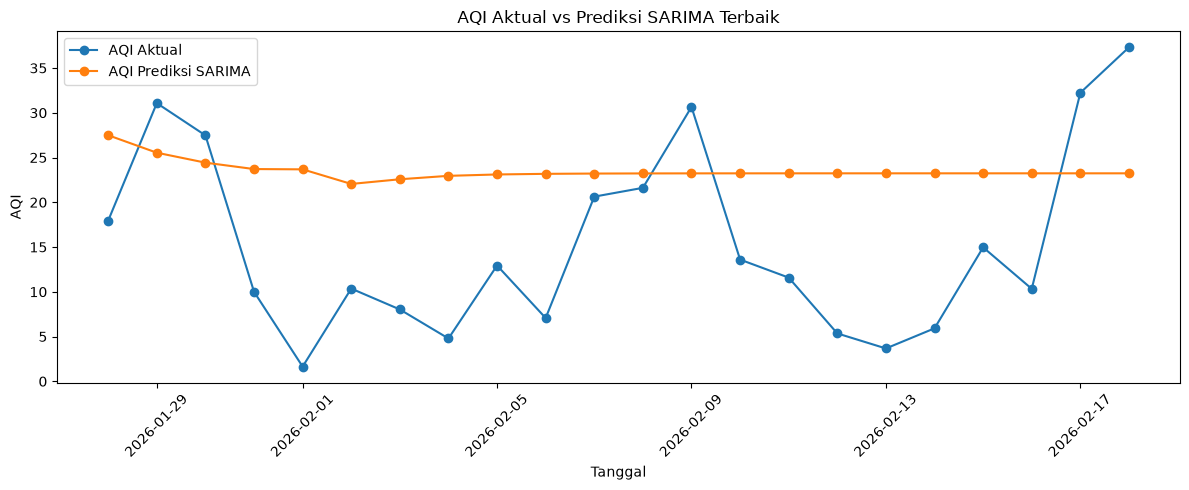

In [14]:
# Langkah 17: Visualisasi aktual vs prediksi

plt.figure(figsize=(12, 5))

plt.plot(
    hasil_prediksi_terbaik.index,
    hasil_prediksi_terbaik["AQI_Aktual"],
    label="AQI Aktual",
    marker="o"
)

plt.plot(
    hasil_prediksi_terbaik.index,
    hasil_prediksi_terbaik["AQI_Prediksi"],
    label="AQI Prediksi SARIMA",
    marker="o"
)

plt.title("AQI Aktual vs Prediksi SARIMA Terbaik")
plt.xlabel("Tanggal")
plt.ylabel("AQI")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 13. Memeriksa residual model SARIMA

Jumlah residual: 86
Rata-rata residual: 1.7630730093290206
Standar deviasi residual: 14.459254020972287


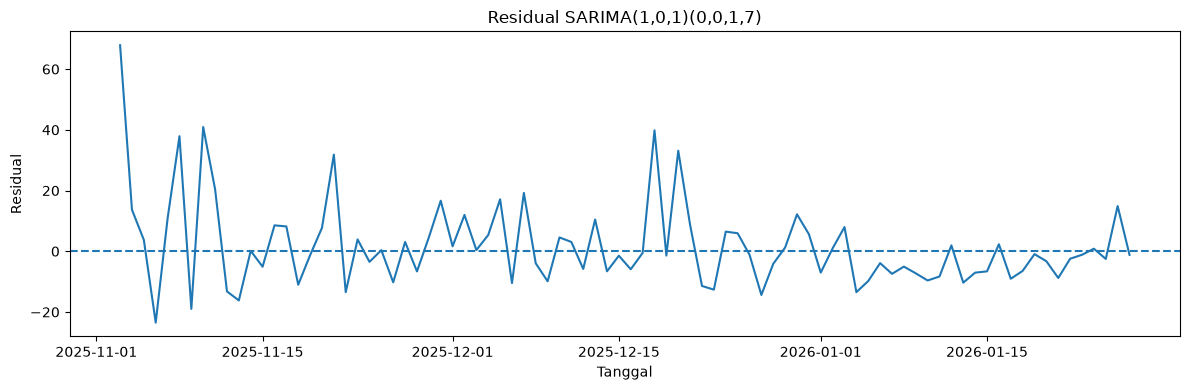

In [15]:
# Langkah 18: Memeriksa residual model SARIMA terbaik

residual_sarima = hasil_sarima_terbaik.resid

print("Jumlah residual:", len(residual_sarima))
print("Rata-rata residual:", residual_sarima.mean())
print("Standar deviasi residual:", residual_sarima.std())

# Grafik residual
plt.figure(figsize=(12, 4))
plt.plot(residual_sarima)
plt.axhline(y=0, linestyle="--")
plt.title("Residual SARIMA(1,0,1)(0,0,1,7)")
plt.xlabel("Tanggal")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

# 14. Menguji autokorelasi residual

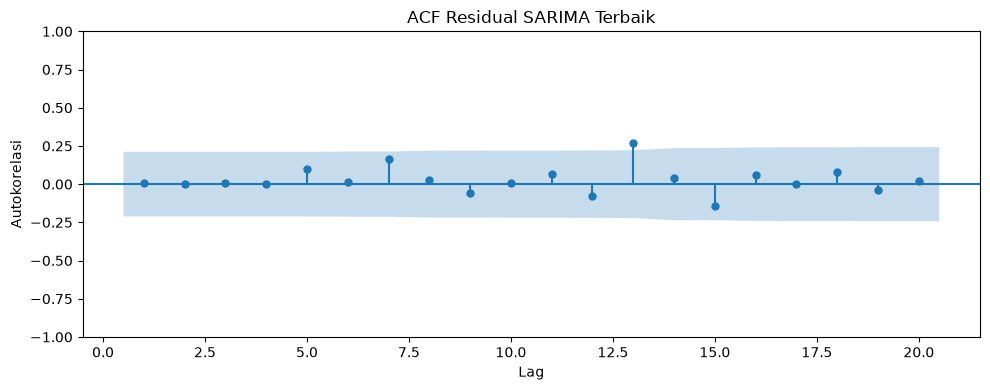

,lb_stat,lb_pvalue
7,3.453551,0.484976
14,12.706710,0.312926


In [16]:
# Langkah 19: ACF residual dan uji Ljung-Box

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

# 1. Grafik ACF residual
fig, ax = plt.subplots(figsize=(10, 4))

plot_acf(
    residual_sarima,
    lags=20,
    zero=False,
    ax=ax
)

ax.set_title("ACF Residual SARIMA Terbaik")
ax.set_xlabel("Lag")
ax.set_ylabel("Autokorelasi")

plt.tight_layout()
plt.show()

# 2. Uji Ljung-Box
hasil_ljungbox = acorr_ljungbox(
    residual_sarima,
    lags=[7, 14],
    model_df=3,
    return_df=True
)

display(hasil_ljungbox)

### interpretasi
1. grafik acf
semua spike berada dalam batas biru, pada spike 13 tampak sedikit menonjol. hal ini menunjukkan tidak terlihat autokorelasi residual yang kuat secara individual pada sebagian besar lag.

2. uji Ljung-Box
- lag7: p-value 0,484976 lebih besar dari 0,05
- lag 14: p-value 0,3129 lebih besar dari 0,05

Residual besar: menunjukkan model melakukan kesalahan pada observasi tertentu.

Residual berpola: menunjukkan masih ada struktur yang mungkin dapat dipelajari oleh model tambahan.

# 15. menyimpan model sarima terbaik dan hasil eksperimen

In [17]:
# Langkah 21: Menyimpan hasil SARIMA terbaik

hasil_prediksi_terbaik.to_csv(
    "prediksi_sarima_terbaik.csv",
    index=True
)

ringkasan_sarima_terbaik = pd.DataFrame({
    "Model": ["SARIMA(1,0,1)(0,0,1,7)"],
    "AIC": [hasil_sarima_terbaik.aic],
    "BIC": [hasil_sarima_terbaik.bic],
    "MAE": [
        mean_absolute_error(
            test["aqi"],
            hasil_prediksi_terbaik["AQI_Prediksi"]
        )
    ],
    "RMSE": [
        np.sqrt(
            mean_squared_error(
                test["aqi"],
                hasil_prediksi_terbaik["AQI_Prediksi"]
            )
        )
    ],
    "MAPE": [
        np.mean(
            np.abs(
                (
                    test["aqi"].to_numpy()
                    - hasil_prediksi_terbaik["AQI_Prediksi"].to_numpy()
                )
                / test["aqi"].to_numpy()
            )
        ) * 100
    ]
})

ringkasan_sarima_terbaik.to_csv(
    "evaluasi_sarima_terbaik.csv",
    index=False
)

display(ringkasan_sarima_terbaik)

print("Hasil SARIMA terbaik berhasil disimpan.")

,Model,AIC,BIC,MAE,RMSE,MAPE
0,"SARIMA(1,0,1)(0,0,1,7)",592.261359,603.980386,11.658289,12.890715,189.338023


Hasil SARIMA terbaik berhasil disimpan.
